In [ ]:
import pandas as pd 
import polars as pl
import numpy as np 

import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats("retina")
import matplotlib as mpl
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "sans-serif"],
    "font.size": 12,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})

import yaml
with open("../../../src/configs.yml", "r") as configs:
    configs = yaml.safe_load(configs)

DATAPATH = configs["SERVER_DATA"]
ROOTPATH = configs["SERVER_WD"]

{'RAW_DATA': '/mnt/RedditData', 'SERVER_WD': '/home/yijingch@asc.upenn.edu/workingdir/reddit-ban-2020', 'SERVER_DATA': '/cinddata/reddit-ban-study'}


## Starting from active subreddits in 2020

In [2]:
# active subreddits in 2020
year = 2020
count_dir = f"{DATAPATH}/data/counts-raw"
active_df = pd.read_parquet(f"{count_dir}/count_submissions_n_item_n_author_minmax_utc_{year}.parquet")
active_df = active_df[~active_df["subreddit"].str.startswith("u_", na=False)] # [new!] fitler out here already!
print(f"# of active subreddits in {year}:", len(active_df))

activity_thres = 10
author_thres = 5

active_df = active_df[(active_df["n_subm"]>=activity_thres)&(active_df["n_subm_author"]>=author_thres)]
all_subrs = active_df["subreddit"].tolist()
# all_subrs = [x for x in all_subrs if x[:2]!="u_"] # [new!] filter out user's own profile
print(f"# of active subreddits in {year} (after filtering):", len(active_df))
print("# of all subreddits:", len(all_subrs))

# notes:
# of active subreddits in 2020: 3329837
# of active subreddits in 2020 (after filtering): 175480
# of all subreddits: 175480


# of active subreddits in 2020: 916538
# of active subreddits in 2020 (after filtering): 175480
# of all subreddits: 175480


In [3]:
active_df

,subreddit,year,n_subm,n_subm_author,min_date,max_date
40,harrymack,2020,193,27,2020-01-08,2020-12-28
57,nerosdayatdisneyland,2020,20,20,2020-01-06,2020-12-12
65,britanyangelus,2020,46,18,2020-01-09,2020-12-16
98,gatesrl,2020,11,8,2020-12-10,2020-12-21
118,amazonunder25,2020,70,19,2020-01-07,2020-12-20
...,...,...,...,...,...,...
3329691,nms_othergalaxies,2020,501,53,2020-01-01,2020-12-31
3329711,shitpostingclub,2020,40,13,2020-01-04,2020-12-29
3329727,opiates,2020,33581,10067,2020-01-01,2020-12-31
3329765,r34frost,2020,38,8,2020-07-14,2020-11-30


In [4]:
# scoping our analysis: how many users were active in these active subreddits?
import glob
count_dir = f"{DATAPATH}/data/counts-raw"
subm_paths = glob.glob(f"{count_dir}/author_subreddit_count_submissions_minmax_utc_*.parquet")
comm_paths = glob.glob(f"{count_dir}/author_subreddit_count_comments_minmax_utc_*.parquet")
subm_count = pl.scan_parquet(subm_paths).collect().rename({"n_subm":"n_posts"}).with_columns(pl.lit("submission").alias("kind"))
comm_count = pl.scan_parquet(comm_paths).collect().rename({"n_comm":"n_posts"}).with_columns(pl.lit("comment").alias("kind"))
post_count = pl.concat(
    [subm_count, comm_count]
    ).filter(
        pl.col("subreddit").is_in(all_subrs) 
        & (pl.col("max_utc") <= pl.datetime(year=2019, month=12, day=31, hour=23, minute=59, second=59))
    )

print(post_count["author"].n_unique())
# this would take about 4 mins
# 57,690,640

57690640


In [5]:
# load count data
count_dir = f"{DATAPATH}/data/counts-raw"
years = range(2006, 2021)
count_df_all = pd.DataFrame()
for this_year in years:
    print("loading:", this_year)
    df = pd.read_parquet(f"{count_dir}/count_joint_n_item_n_author_minmax_utc_{this_year}.parquet")
    df["year"] = this_year
    count_df_all = pd.concat([df, count_df_all])

count_df_all["min_date"] = pd.to_datetime(count_df_all["min_date"])
count_df_all["max_date"] = pd.to_datetime(count_df_all["max_date"])
count_df_all = count_df_all[count_df_all["subreddit"].str.len()>0]

count_df_all.head()

loading: 2006
loading: 2007
loading: 2008
loading: 2009
loading: 2010
loading: 2011
loading: 2012
loading: 2013
loading: 2014
loading: 2015
loading: 2016
loading: 2017
loading: 2018
loading: 2019
loading: 2020


,subreddit,year,n_comm,n_subm,n_comm_author,n_subm_author,n_author,min_date,max_date
0,u_ancientswastika,2020,0,1,0,1,1,2020-08-30,2020-08-30
1,u_papiss187,2020,0,1,0,1,1,2020-08-18,2020-08-18
2,treeboas,2020,0,3,0,2,2,2020-02-14,2020-12-15
3,u_richprowriterq,2020,0,4,0,1,1,2020-02-22,2020-08-02
4,u_uhhhhskinnypelican,2020,0,1,0,1,1,2020-01-18,2020-01-18


### calculate lifetime

In [6]:
# calculate lifetime
count_aggr = count_df_all.groupby("subreddit").agg(
    min_date=("min_date", "min"),
    max_date=("max_date", "max"),
    # n_subm_all=("n_subm", "sum")
    ).reset_index()
count_aggr["min_year"] = count_aggr["min_date"].dt.year
count_aggr["max_year"] = count_aggr["max_date"].dt.year

ref_date = pd.to_datetime("2019-12-31")  # [new!]
count_aggr["lifetime_d"] = (ref_date - count_aggr["min_date"]).dt.days + 1
count_aggr["lifetime_y"] = 2019 - count_aggr["min_year"] + 1
born2020 = count_aggr[count_aggr["lifetime_d"]<=0]["subreddit"].tolist() # subreddits that were created in 2020
count_aggr

,subreddit,min_date,max_date,min_year,max_year,lifetime_d,lifetime_y
0,*cohold00009,2018-12-05,2018-12-06,2018,2018,392,2
1,*cohold00022,2019-08-01,2019-12-17,2019,2019,153,1
2,*polhold00214,2018-04-25,2018-10-22,2018,2018,616,2
3,*polhold00575,2019-06-13,2019-06-13,2019,2019,202,1
4,*polhold999999,2018-10-18,2018-10-18,2018,2018,440,2
...,...,...,...,...,...,...,...
6975217,zzzzzzzzzzzzzzzzzzzza,2020-08-03,2020-08-03,2020,2020,-215,0
6975218,zzzzzzzzzzzzzzzzzzzzm,2020-05-23,2020-05-23,2020,2020,-143,0
6975219,zzzzzzzzzzzzzzzzzzzzx,2020-09-08,2020-09-22,2020,2020,-251,0
6975220,zzzzzzzzzzzzzzzzzzzzy,2019-08-04,2019-08-04,2019,2019,150,1


### count cumulative activities

In [7]:
count_aggr_till2019 = count_df_all[count_df_all["year"]<=2019].groupby("subreddit").agg(
    n_subm_till2019=("n_subm", "sum"),
    n_comm_till2019=("n_comm", "sum")
    ).reset_index()
count_aggr_till2019.head()

,subreddit,n_subm_till2019,n_comm_till2019
0,*cohold00009,3,0
1,*cohold00022,46,0
2,*polhold00214,3,0
3,*polhold00575,3,0
4,*polhold999999,2,0


### load banned subreddits!

In [8]:
banned_df = pd.read_csv(f"{DATAPATH}/index/banned_subreddits_cleaned_251006_add_filter.csv")
banned_df = banned_df[banned_df["active_filter"]==1]
print(banned_df["reason"].unique())
banned_subrs = banned_df["subreddit"].tolist()

ban_born2020 = set(banned_subrs).intersection(set(born2020))
print("# of subreddits that were born and banned in 2020:", len(ban_born2020))

['unmoderated' 'harassment_or_violence' 'copyright' 'regulation_evasion'
 'sexual_content' 'prohibited_transaction' 'spam' 'no_specific_reason'
 'privacy' 'impersonating' 'illegal_activity']
# of subreddits that were born and banned in 2020: 1619


In [ ]:
conn_list = pd.read_parquet(f"{DATAPATH}/data/counts-raw/"
                            "n_overlap_user_post_w_banned-2020-3274_thresholded.parquet")

conn_list

,subreddit,u_overlap_min_post_ban_1,u_overlap_min_post_ban_2,u_overlap_min_post_ban_3,u_overlap_min_post_ban_5,u_overlap_min_post_ban_10,u_overlap_min_post_ban_20,u_overlap_min_post_ban_30,u_overlap_min_post_ban_50,u_overlap_min_post_ban_100
0,askreddit,807800,516392,400834,293658,193751,128904,102045,75631,49250
1,the_donald,729968,478834,381662,290161,201323,140482,113833,86348,57776
2,pics,582911,385513,304126,227102,153249,104411,83828,63224,42181
3,funny,589145,382429,298319,220027,146038,98139,78231,58587,38802
4,worldnews,485894,338783,274481,210898,146886,102603,83408,63738,43070
...,...,...,...,...,...,...,...,...,...,...
653678,cigar_deals,1,0,0,0,0,0,0,0,0
653679,manafest,1,0,0,0,0,0,0,0,0
653680,bacriti,1,1,0,0,0,0,0,0,0
653681,anal_bros,3,1,0,0,0,0,0,0,0


In [10]:
pool_df = pd.DataFrame()
pool_df["subreddit"] = all_subrs
pool_df = pool_df.merge(conn_list, how="left", on="subreddit").fillna(0)
pool_df = pool_df.merge(count_aggr[["subreddit","lifetime_d"]], on="subreddit", how="left")
pool_df["if_banned"] = pool_df["subreddit"].map(lambda x: 1 if x in banned_subrs else 0)
pool_df = pool_df[(pool_df["lifetime_d"]>0)&(pool_df["if_banned"]==0)]
pool_df

,subreddit,u_overlap_min_post_ban_1,u_overlap_min_post_ban_2,u_overlap_min_post_ban_3,u_overlap_min_post_ban_5,u_overlap_min_post_ban_10,u_overlap_min_post_ban_20,u_overlap_min_post_ban_30,u_overlap_min_post_ban_50,u_overlap_min_post_ban_100,lifetime_d,if_banned
0,harrymack,6.0,5.0,5.0,3.0,1.0,1.0,1.0,1.0,1.0,1075,0
1,nerosdayatdisneyland,7.0,6.0,6.0,5.0,5.0,4.0,3.0,3.0,2.0,1391,0
2,britanyangelus,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,29,0
4,amazonunder25,128.0,79.0,63.0,52.0,35.0,25.0,21.0,15.0,11.0,1932,0
5,tabled,384.0,281.0,226.0,174.0,117.0,84.0,70.0,48.0,32.0,2876,0
...,...,...,...,...,...,...,...,...,...,...,...,...
175471,motor,28.0,18.0,14.0,8.0,4.0,2.0,2.0,2.0,1.0,4046,0
175472,vintagefashions,73.0,50.0,39.0,32.0,23.0,15.0,12.0,10.0,6.0,1734,0
175475,nms_othergalaxies,18.0,16.0,14.0,11.0,8.0,6.0,5.0,4.0,3.0,345,0
175476,shitpostingclub,37.0,27.0,26.0,22.0,17.0,12.0,11.0,9.0,7.0,293,0


In [24]:
pool_df[f"u_overlap_min_post_ban_5"].max()
# 807800

293658.0

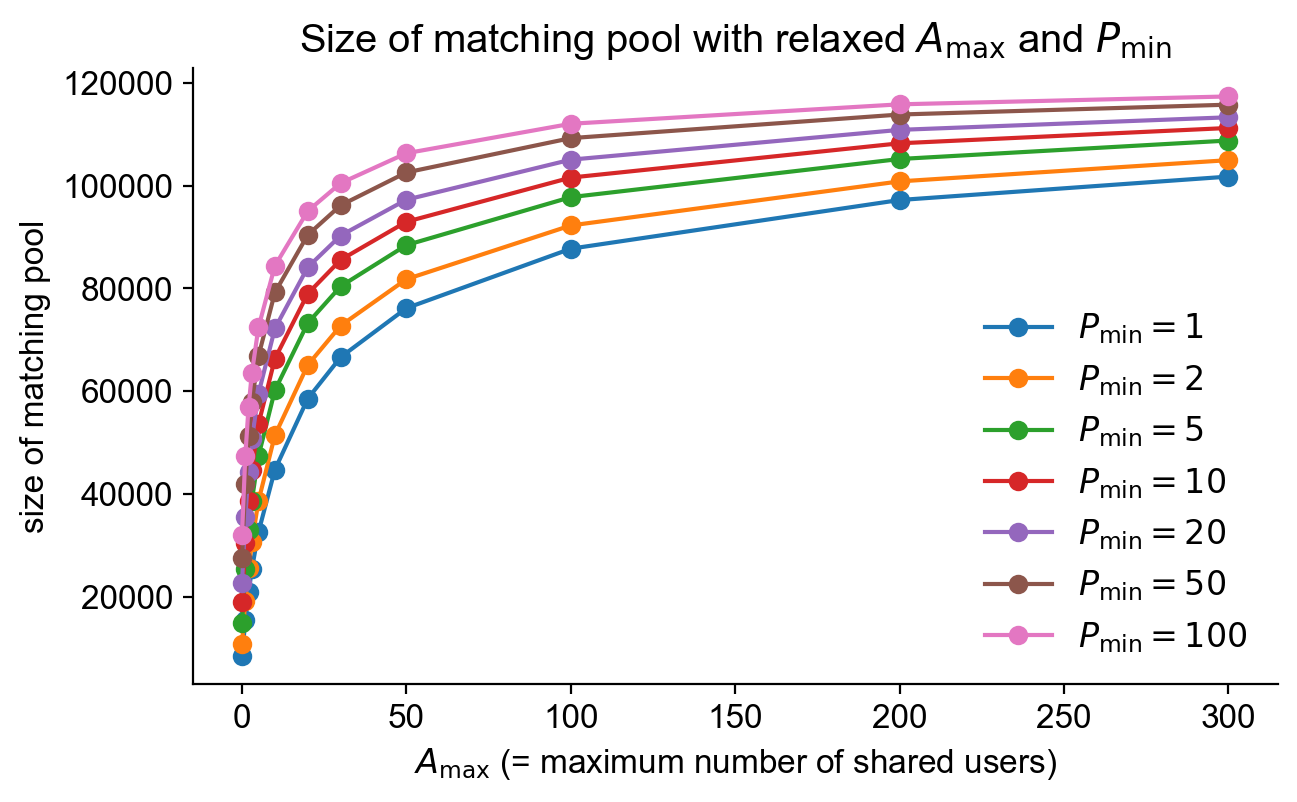

In [ ]:
# show the varying matching size with different X and N
pool_size_df = pd.DataFrame()
Xs = [0,1,2,3,5,10,20,30,50,100,200,300,5001e7]
Ns = [1,2,5,10,20,50,100]
pool_size_df["X"] = Xs
for n in Ns:
    pool_size_df[f"N_{n}"] = [len(pool_df[pool_df[f"u_overlap_min_post_ban_{n}"]<=x]) for x in Xs]
# print(pool_size_df)

fig,ax = plt.subplots(figsize=(7,4))
for n in Ns:
    # plt.plot(pool_size_df[f"N_{n}"], label=fr"$P_{{\min}} = {n}$")
    ax.plot(
        Xs[:-1],                         # actual A_max values
        pool_size_df[f"N_{n}"][:-1],    # exclude "no limit"
        marker="o",
        label=fr"$P_{{\min}} = {n}$"
    )

# plt.xticks(range(len(Xs)), Xs[:-1]+["no\nlimit"])
plt.ylabel("size of matching pool", fontsize=12)
plt.xlabel(r"$A_{\max}$ (= maximum number of shared users)", fontsize=12)
plt.legend(loc=4)
plt.title(r"Size of matching pool with relaxed $A_{\max}$ and $P_{\min}$")
plt.savefig("../../../output/appendix/matching-pool-sizes-Amax-Pmin.png", dpi=300, bbox_inches="tight")
plt.savefig("../../../output/appendix/matching-pool-sizes-Amax-Pmin.pdf", dpi=300, bbox_inches="tight")

In [10]:
match_df = pd.DataFrame()
match_df["subreddit"] = all_subrs

print("building treatment column...")
match_df["if_banned"] = match_df["subreddit"].map(lambda x: 1 if x in banned_subrs else 0)
match_df["if_banned_born2020"] = match_df["subreddit"].map(lambda x: 1 if x in ban_born2020 else 0)

print("building pretreatment covariate columns...")
# lifetime
match_df = match_df.merge(count_aggr[["min_year","subreddit","lifetime_d","lifetime_y"]], on="subreddit", how="left")

# number of posts till 2019
match_df = match_df.merge(count_aggr_till2019, on="subreddit", how="left").fillna(0)
match_df["n_post_till2019"] = match_df["n_subm_till2019"] + match_df["n_comm_till2019"]
match_df["n_post_till2019_log"] = match_df["n_post_till2019"].map(lambda x: np.log1p(x))

# number of authors, posts in 2019
activity_df = pd.read_parquet(f"{count_dir}/count_joint_n_item_n_author_minmax_utc_2019.parquet")
activity_df["n_post"] = activity_df["n_subm"] + activity_df["n_comm"]
activity_dict = activity_df.set_index("subreddit").to_dict()["n_author"]
activity_dict2 = activity_df.set_index("subreddit").to_dict()["n_post"]
match_df["n_post_author2019"] = match_df["subreddit"].map(lambda x: activity_dict[x] if x in activity_dict.keys() else 0)
match_df["n_post2019"] = match_df["subreddit"].map(lambda x: activity_dict2[x] if x in activity_dict2.keys() else 0)
match_df["n_post_author2019_log"] = match_df["n_post_author2019"].map(lambda x: np.log1p(x))
match_df["n_post2019_log"] = match_df["n_post2019"].map(lambda x: np.log1p(x))

# number of authors till 2019
acc_activity_df = pd.read_parquet(f"{count_dir}/2020active_subreddits_175480_acc_n_post_author.parquet")
acc_activity_dict = acc_activity_df.set_index("subreddit").to_dict()["acc_post_author2019"]
match_df["n_post_author_till2019"] = match_df["subreddit"].map(lambda x: acc_activity_dict[x] if x in activity_dict.keys() else 0)
match_df["n_post_author_till2019_log"] = match_df["n_post_author_till2019"].map(lambda x: np.log1p(x))

# add pool sizing params
match_df = match_df.merge(pool_df.drop(columns=["lifetime_d", "if_banned"]),on="subreddit",how="left")
match_df

building treatment column...


building pretreatment covariate columns...


,subreddit,if_banned,if_banned_born2020,min_year,lifetime_d,lifetime_y,n_subm_till2019,n_comm_till2019,n_post_till2019,n_post_till2019_log,...,n_post_author_till2019_log,u_overlap_min_post_ban_1,u_overlap_min_post_ban_2,u_overlap_min_post_ban_3,u_overlap_min_post_ban_5,u_overlap_min_post_ban_10,u_overlap_min_post_ban_20,u_overlap_min_post_ban_30,u_overlap_min_post_ban_50,u_overlap_min_post_ban_100
0,harrymack,0,0,2017,1075,3,57.0,25.0,82.0,4.418841,...,2.833213,6.0,5.0,5.0,3.0,1.0,1.0,1.0,1.0,1.0
1,nerosdayatdisneyland,0,0,2016,1391,4,83.0,96.0,179.0,5.192957,...,3.583519,7.0,6.0,6.0,5.0,5.0,4.0,3.0,3.0,2.0
2,britanyangelus,0,0,2019,29,1,6.0,0.0,6.0,1.945910,...,1.098612,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,gatesrl,0,0,2020,-344,0,0.0,0.0,0.0,0.000000,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,amazonunder25,0,0,2014,1932,6,2136.0,516.0,2652.0,7.883446,...,6.666957,128.0,79.0,63.0,52.0,35.0,25.0,21.0,15.0,11.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175475,nms_othergalaxies,0,0,2019,345,1,396.0,1119.0,1515.0,7.323831,...,4.727388,18.0,16.0,14.0,11.0,8.0,6.0,5.0,4.0,3.0
175476,shitpostingclub,0,0,2019,293,1,446.0,555.0,1001.0,6.909753,...,4.553877,37.0,27.0,26.0,22.0,17.0,12.0,11.0,9.0,7.0
175477,opiates,0,0,2010,3584,10,236820.0,3584978.0,3821798.0,15.156232,...,11.439795,13283.0,9384.0,7619.0,5836.0,4043.0,2755.0,2154.0,1600.0,1019.0
175478,r34frost,0,0,2020,-195,0,0.0,0.0,0.0,0.000000,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
match_df.head(2).T

,0,1
subreddit,harrymack,nerosdayatdisneyland
if_banned,0,0
if_banned_born2020,0,0
min_year,2017,2016
lifetime_d,1075,1391
lifetime_y,3,4
n_subm_till2019,57.0,83.0
n_comm_till2019,25.0,96.0
n_post_till2019,82.0,179.0
n_post_till2019_log,4.418841,5.192957


In [12]:
# match_df.to_csv(f"{DATAPATH}/data/samples/to_match_table_selfid_banned_3274_260528.csv", index=False)